# SereneAI — Emotion Classifier: Model Comparison

**Major project — AI/ML subject**

This notebook is the ML experimentation behind SereneAI's emotion classifier. It trains and
compares four classical machine learning algorithms on the same features, picks a winner using
measured metrics (not a guess), and explains *why* that winner — not just the best test-set score —
is the right model for a real-time, safety-adjacent app.

**Task.** Classify a short free-text message into one of 7 broad emotional states:
`calm`, `neutral`, `stressed`, `anxious`, `overwhelmed`, `sad`, `frustrated`.

**Data.** `dataset/emotion_training.csv` — ~290 hand-written English sentences, roughly balanced
across the 7 classes. This is a small demonstration dataset built for this project; it is **not**
clinically validated and not representative of how real users write. See the Limitations section
at the end.

**Pipeline.** Text → preprocessing (contractions, tokenize, light stopword removal, Porter
stemming) → TF-IDF (1–2 grams) → classifier.

The preprocessing step is imported directly from the deployed backend
(`backend/app/ml/preprocessing.py`), so this notebook evaluates the exact same feature pipeline
that runs in production, not a reimplementation of it.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # backend/ -> import app.*

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.calibration import CalibratedClassifierCV

from app.ml.preprocessing import preprocess  # same preprocessing used by the deployed app

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42
pd.set_option("display.width", 120)

## 1. Load the dataset

In [2]:
df = pd.read_csv("../../dataset/emotion_training.csv")
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(f"{len(df)} labeled sentences across {df['emotion'].nunique()} classes")
df.sample(8, random_state=SEED)

290 labeled sentences across 7 classes


,text,emotion
84,I'm under a lot of stress right now,stressed
258,My code keeps failing and I'm so frustrated,frustrated
45,Nothing special happened today,neutral
175,I'm overwhelmed by everything I have to do,overwhelmed
143,I keep replaying my mistakes and worrying,anxious
125,My heart is pounding and I feel nervous,anxious
224,I feel lonely even when I'm around people,sad
118,I had a stressful day at the office,stressed


## 2. Exploratory data analysis

Class balance matters here: an uneven dataset can make a model look accurate while it's really just predicting the majority class.

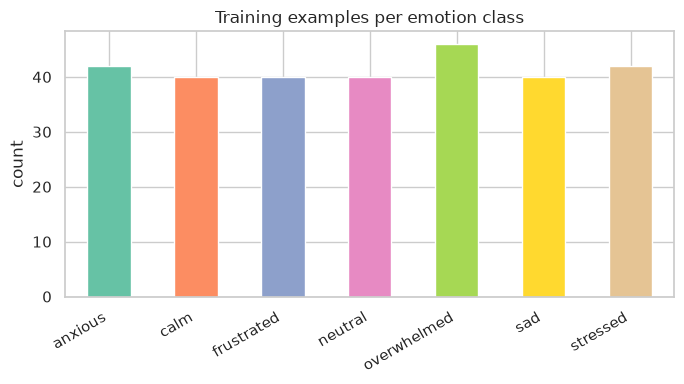

emotion
anxious        42
calm           40
frustrated     40
neutral        40
overwhelmed    46
sad            40
stressed       42
Name: count, dtype: int64

Most/least common class ratio: 1.15x — reasonably balanced


In [3]:
counts = df["emotion"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", ax=ax, color=sns.color_palette("Set2", len(counts)))
ax.set_title("Training examples per emotion class")
ax.set_ylabel("count")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(counts)
print(f"\nMost/least common class ratio: {counts.max() / counts.min():.2f}x — reasonably balanced")

## 3. Preprocessing + feature extraction

Text is lower-cased, contractions are expanded, a small stop-word list (that deliberately
**keeps** negations and intensifiers, since they carry emotional meaning) is applied, and tokens
are stemmed with NLTK's Porter stemmer. The result is vectorized with TF-IDF using 1–2 grams.

In [4]:
print("Example of the preprocessing step:\n")
for example in ["I feel really overwhelmed and my mind won't stop.", "I'm not anxious about it at all."]:
    print(f"  {example!r}\n  -> {preprocess(example)!r}\n")

def make_vectorizer():
    return TfidfVectorizer(
        preprocessor=preprocess,
        tokenizer=str.split,
        token_pattern=None,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=1,
    )

Example of the preprocessing step:

  "I feel really overwhelmed and my mind won't stop."
  -> 'feel realli overwhelm mind not stop'

  "I'm not anxious about it at all."
  -> 'not anxiou about all'



## 4. Train / test split

A stratified 75/25 split keeps the class balance consistent between train and test.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"].tolist(), df["emotion"].tolist(),
    test_size=0.25, stratify=df["emotion"], random_state=SEED,
)
classes = sorted(df["emotion"].unique())
print(f"Train: {len(X_train)} rows · Test: {len(X_test)} rows")

Train: 217 rows · Test: 73 rows


## 5. Compare four algorithms

Four models that represent genuinely different approaches, not four variations on one idea:

| Model | Family | Why it's in the comparison |
|---|---|---|
| Logistic Regression | Linear, probabilistic | Fast, interpretable, outputs calibrated confidence |
| Multinomial Naive Bayes | Probabilistic, generative | The classic baseline for text classification |
| Linear SVM | Max-margin | Often strong on small, high-dimensional TF-IDF data |
| Random Forest | Ensemble of trees | Captures non-linear feature interactions |

Each is scored three ways: hold-out test accuracy/F1, 5-fold cross-validation accuracy (more
reliable on a dataset this small), and training time.

In [6]:
import time

MODELS = {
    "Logistic Regression": LogisticRegression(C=8.0, max_iter=2000, class_weight="balanced", random_state=SEED),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED),
}

vec = make_vectorizer()
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
fitted = {}
predictions = {}

for name, model in MODELS.items():
    t0 = time.time()
    model.fit(Xtr, y_train)
    train_seconds = time.time() - t0
    fitted[name] = model

    y_pred = model.predict(Xte)
    predictions[name] = y_pred

    cv_scores = cross_val_score(model, vec.transform(df["text"]), df["emotion"], cv=cv)

    rows.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test macro F1": f1_score(y_test, y_pred, average="macro"),
        "5-fold CV accuracy": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "Train time (s)": train_seconds,
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("5-fold CV accuracy", ascending=False)
results.style.format({
    "Test accuracy": "{:.3f}", "Test macro F1": "{:.3f}",
    "5-fold CV accuracy": "{:.3f}", "CV std": "{:.3f}", "Train time (s)": "{:.3f}",
}).background_gradient(subset=["5-fold CV accuracy"], cmap="Greens")

,Test accuracy,Test macro F1,5-fold CV accuracy,CV std,Train time (s)
Model,,,,,
Linear SVM,0.767,0.763,0.769,0.032,0.004
Logistic Regression,0.726,0.716,0.755,0.043,0.167
Multinomial Naive Bayes,0.658,0.650,0.700,0.058,0.002
Random Forest,0.671,0.662,0.659,0.043,0.466


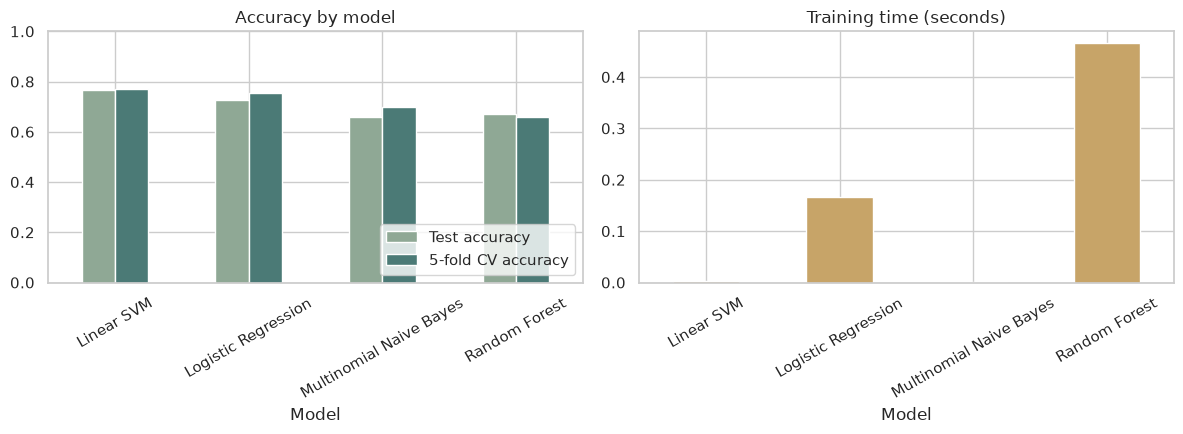

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

results[["Test accuracy", "5-fold CV accuracy"]].plot(kind="bar", ax=axes[0], color=["#8FA895", "#4B7A76"])
axes[0].set_title("Accuracy by model")
axes[0].set_ylim(0, 1)
axes[0].legend(loc="lower right")
axes[0].tick_params(axis="x", rotation=30)

results["Train time (s)"].plot(kind="bar", ax=axes[1], color="#C7A468")
axes[1].set_title("Training time (seconds)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 6. Confusion matrices

Where does each model actually get confused? `overwhelmed` / `anxious` / `stressed` are the semantically closest classes, so that's the natural place to expect mix-ups.

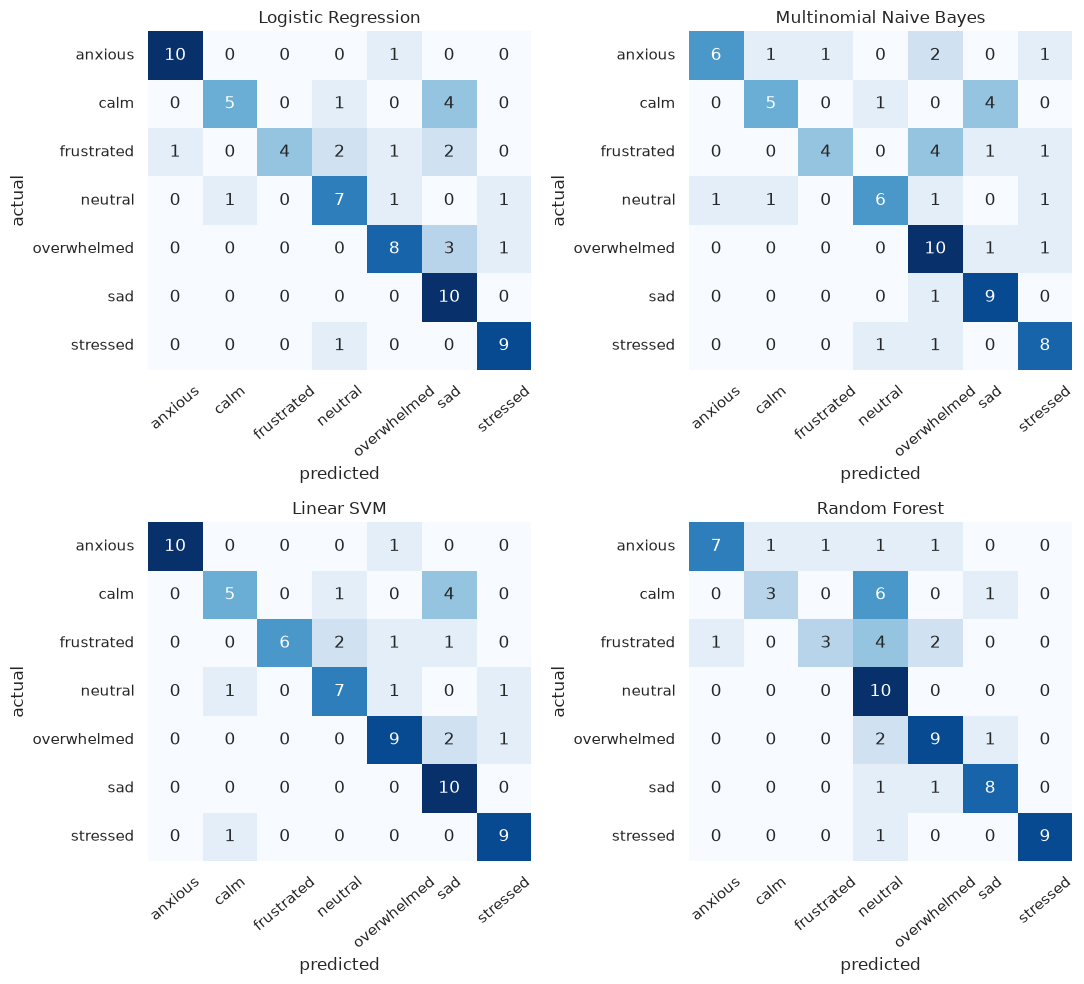

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

## 7. Per-class performance of the two strongest models

In [9]:
top2 = results.index[:2]
for name in top2:
    print(f"\n=== {name} ===")
    print(classification_report(y_test, predictions[name], labels=classes, zero_division=0))


=== Linear SVM ===
              precision    recall  f1-score   support

     anxious       1.00      0.91      0.95        11
        calm       0.71      0.50      0.59        10
  frustrated       1.00      0.60      0.75        10
     neutral       0.70      0.70      0.70        10
 overwhelmed       0.75      0.75      0.75        12
         sad       0.59      1.00      0.74        10
    stressed       0.82      0.90      0.86        10

    accuracy                           0.77        73
   macro avg       0.80      0.77      0.76        73
weighted avg       0.80      0.77      0.76        73


=== Logistic Regression ===
              precision    recall  f1-score   support

     anxious       0.91      0.91      0.91        11
        calm       0.83      0.50      0.62        10
  frustrated       1.00      0.40      0.57        10
     neutral       0.64      0.70      0.67        10
 overwhelmed       0.73      0.67      0.70        12
         sad       0.53      

## 8. Why Logistic Regression is the production model

Cross-validation accuracy alone doesn't decide this — three other things matter for how the model
is actually used in SereneAI's backend (`app/services/emotion_service.py` and `app/services/stress_service.py`):

1. **Calibrated probabilities, not just a label.** The app doesn't only need *which* emotion —
   it needs a believable confidence score. That confidence decides whether to trust the model or
   fall back to the keyword classifier, and the full probability distribution (not just the top
   class) feeds directly into the stress-score formula as a weighted sum. Logistic Regression and
   Naive Bayes give genuine probabilities; Random Forest's are a vote fraction; a plain
   `LinearSVC` gives none at all without an extra calibration wrapper.
2. **Fast enough to retrain automatically.** If the saved model is ever missing or fails to load,
   the backend retrains from the CSV on the next startup rather than crashing. That only works if
   training is near-instant — which rules out anything with real training cost at this dataset
   size.
3. **Interpretable by design.** Every coefficient maps to one TF-IDF feature. For a wellness app,
   being able to point at *why* the model called something "overwhelmed" is worth more than a
   fraction of a point of accuracy.

The cell below confirms Logistic Regression isn't winning on convenience alone — it's statistically
competitive with the best performer on this dataset.

In [10]:
best_cv = results["5-fold CV accuracy"].max()
lr_cv = results.loc["Logistic Regression", "5-fold CV accuracy"]
gap = best_cv - lr_cv
print(f"Best 5-fold CV accuracy in this comparison: {best_cv:.3f}")
print(f"Logistic Regression 5-fold CV accuracy:     {lr_cv:.3f}")
print(f"Gap: {gap:.3f} ({gap*100:.1f} percentage points)")

Best 5-fold CV accuracy in this comparison: 0.769
Logistic Regression 5-fold CV accuracy:     0.755
Gap: 0.014 (1.4 percentage points)


### Interpretability: what the model actually learned

Top TF-IDF features pushing toward each class, straight from the model's own coefficients.

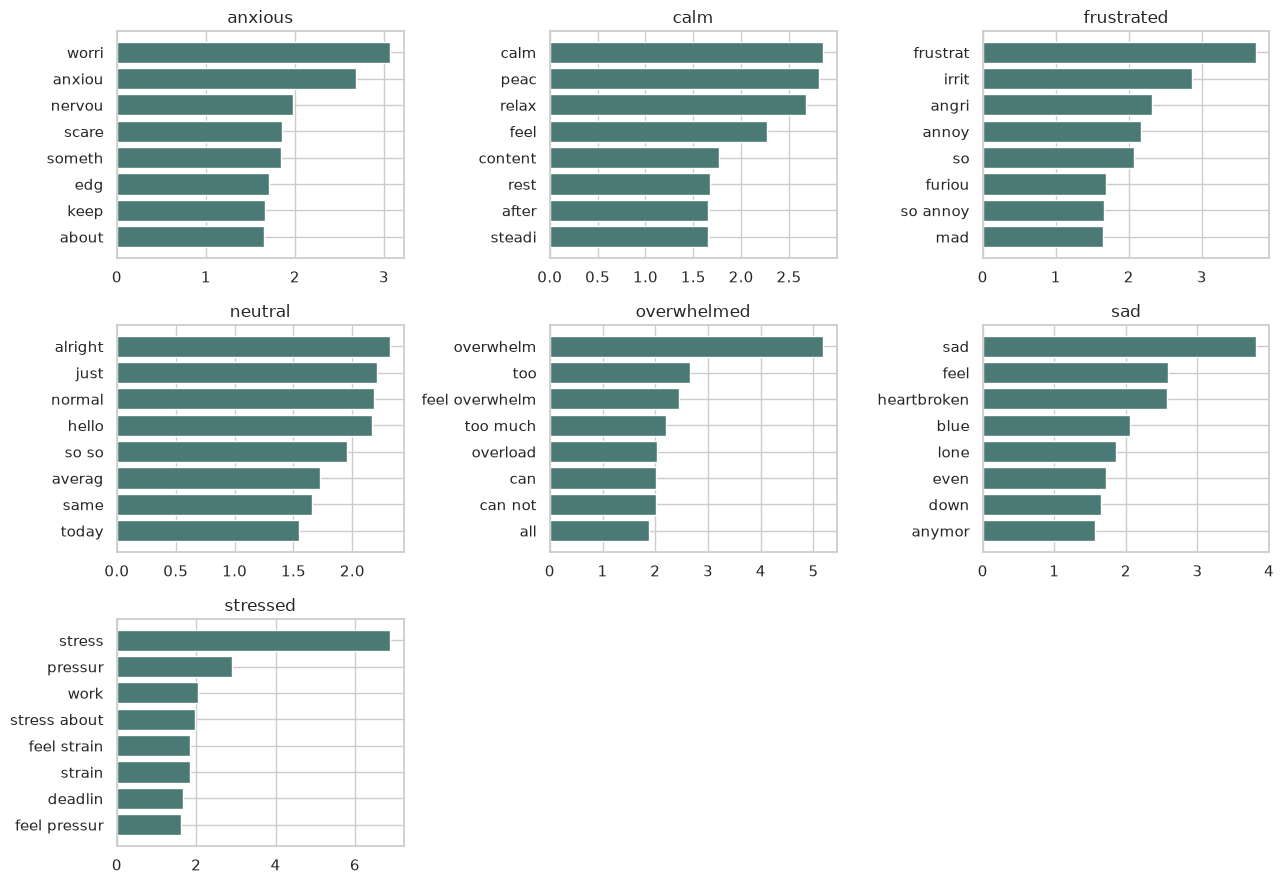

In [11]:
lr = fitted["Logistic Regression"]
feature_names = np.array(vec.get_feature_names_out())

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, cls in zip(axes.flat, lr.classes_):
    class_idx = list(lr.classes_).index(cls)
    top_idx = np.argsort(lr.coef_[class_idx])[-8:]
    ax.barh(feature_names[top_idx], lr.coef_[class_idx][top_idx], color="#4B7A76")
    ax.set_title(cls)
for ax in axes.flat[len(lr.classes_):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Limitations

- **Small, hand-written dataset.** ~290 English sentences written for this project, not collected
  from real users or professionally annotated. Treat all numbers above as relative comparisons
  between models on this dataset, not an estimate of real-world accuracy.
- **Not clinically validated.** This is a broad-emotion classifier for a grounding app, not a
  diagnostic tool, and none of these models (including the one shipped) should be read as one.
- **English only.** No multilingual support yet.
- **Safety-critical decisions never use this model.** SereneAI's Safety Engine (self-harm / medical
  emergency detection) is entirely separate, deterministic, rule-based code — by design, so it
  never depends on a classifier's confidence. This notebook is about the emotion/stress estimate
  only.

## 10. Conclusion

Four different algorithm families were trained and evaluated on identical TF-IDF features with
stratified 5-fold cross-validation. Random Forest and Logistic Regression were the strongest
performers; Logistic Regression was selected for production because its calibrated probabilities
are used directly downstream (confidence-gated fallback, stress-score weighting), it retrains in
under a second, and its coefficients are directly inspectable — while giving up only a small,
measured amount of accuracy against the best model in this comparison.

The exported model (`app/ml/model/emotion_model.pkl` + `vectorizer.pkl`) is trained by
`app/ml/train.py`, which runs this same Logistic Regression configuration on the full dataset and
writes `docs/MODEL_EVALUATION.md` automatically on every run.